### Plot Lava flows

This script reads a file output from MOLASSES multivent and plots the map of area inundated by the lava flow.



In [2]:
import pandas as pd

#first flow
colnames=['EAST', 'NORTH', 'THICKNESS', 'NEW_ELEV', 'ORIG_ELEV'] 
#lava1 = pd.read_csv('./flow_NRF_30mdem_1e4_20m', skiprows=3, names=colnames, delim_whitespace=True, header= None)
lava1 = pd.read_csv('./flow_CFPP-0_81m_1e5', skiprows=3, names=colnames, delim_whitespace=True, header= None)

print("column types:", lava1.dtypes)

#lava.head(10)

lava_east1, lava_north1 = lava1["EAST"].values, lava1["NORTH"].values

#second flow
colnames=['EAST', 'NORTH', 'THICKNESS', 'NEW_ELEV', 'ORIG_ELEV'] 
#lava2 = pd.read_csv('./flow_NRF_81mdem_1e4_20m', skiprows=3, names=colnames, delim_whitespace=True, header= None)
lava2 = pd.read_csv('./flow_CFPP-0_30_1e5', skiprows=3, names=colnames, delim_whitespace=True, header= None)

print("column types:", lava2.dtypes)

#lava.head(10)

lava_east2, lava_north2 = lava2["EAST"].values, lava2["NORTH"].values

# vent data should be the same
# ventnames = ['volume', 'pulse', 'residual','vent1_east', 'vent1_north']
# vent = pd.read_csv('./flow_NRF_30mdem_1e4', skiprows=1, nrows = 1, names=ventnames, delim_whitespace=True, header= None)
# vent.head(1)

# vent_east, vent_north = vent["vent1_east"].values, vent["vent1_north"].values




column types: EAST         float64
NORTH        float64
THICKNESS    float64
NEW_ELEV     float64
ORIG_ELEV    float64
dtype: object
column types: EAST         float64
NORTH        float64
THICKNESS    float64
NEW_ELEV     float64
ORIG_ELEV    float64
dtype: object


/tmp/ipykernel_1948/874656790.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  lava1 = pd.read_csv('./flow_CFPP-0_81m_1e5', skiprows=3, names=colnames, delim_whitespace=True, header= None)
/tmp/ipykernel_1948/874656790.py:17: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  lava2 = pd.read_csv('./flow_CFPP-0_30_1e5', skiprows=3, names=colnames, delim_whitespace=True, header= None)


In [3]:

colnames=['EAST', 'NORTH'] 
all_vents = pd.read_csv('./ESRP_vents.ll', skiprows=0, names=colnames, delim_whitespace=True, header= None)

print("column types:", all_vents.dtypes)

#lava.head(10)

all_vents_east, all_vents_north = all_vents["EAST"].values, all_vents["NORTH"].values


column types: EAST     float64
NORTH    float64
dtype: object


/tmp/ipykernel_1948/1922362803.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  all_vents = pd.read_csv('./ESRP_vents.ll', skiprows=0, names=colnames, delim_whitespace=True, header= None)


'\nax.plot(-112.8683, 43.5481,  marker=\'o\', linestyle=\'None\', color=\'green\', markersize=5,\n             alpha=0.7, transform=ccrs.Geodetic())\nax.text(-112.8683, 43.5481,\n         "CITRC",\n         color="red", fontsize=10,\n         horizontalalignment="center", verticalalignment="bottom",\n         transform=ccrs.Geodetic()) ## Important\n\nax.plot(-112.93313, 43.57071,  marker=\'o\', linestyle=\'None\', color=\'green\', markersize=5,\n             alpha=0.7, transform=ccrs.Geodetic())\nax.text(-112.93313, 43.57071,\n         "INTEC",\n         color="red", fontsize=10,\n         horizontalalignment="center", verticalalignment="bottom",\n         transform=ccrs.Geodetic()) ## Important\n\nax.plot(-112.971940, 43.589230,  marker=\'o\', linestyle=\'None\', color=\'green\', markersize=5,\n             alpha=0.7, transform=ccrs.Geodetic())\nax.text(-112.971940, 43.589230,\n         "ATRC",\n         color="red", fontsize=10,\n         horizontalalignment="center", verticalalignm

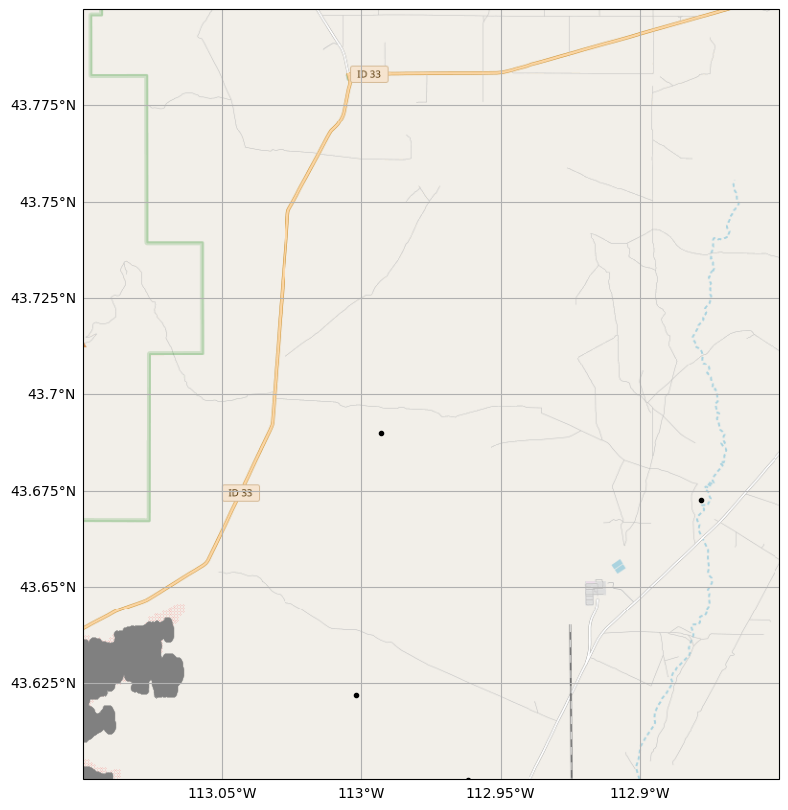

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io.img_tiles import OSM

from pyproj import Geod

fig = plt.figure(figsize=(10,10))

#use a terrain background (Stamen)
# this is not the same as the DEM used to run the simulation

tiler = OSM()
mercator = tiler.crs
ax = plt.axes(projection=mercator) #use a mercator map projection

#Map extent is changed form
#previous example to zoom in
ax.set_extent((-113.1, -112.85, 43.6, 43.8))

#Increase the zoom level for more resolution on the terrain
zoom = 12
ax.add_image(tiler, zoom)


#plot lavas
# the lava flow is plotted as a marker. There are so many
# markers it wappears to be a solid shaded area
# notice that the input is assumed to be UTM zone 12
# matching the output from MOLASSES
ax.plot(lava_east1, lava_north1, marker='.', linestyle='None', color='red', markersize=0.2,
             alpha=0.7, transform=ccrs.UTM(zone="12"))

ax.plot(lava_east2, lava_north2, marker='s', linestyle='None', color='gray', markersize=2,
             alpha=0.5, transform=ccrs.UTM(zone="12"))

#plot all the volcano vents that have already erupted
ax.plot(all_vents_east, all_vents_north, marker='o', linestyle='None', color='black', markersize=3,
             alpha=1, transform=ccrs.Geodetic())

# Plot the volcano vent location
ax.plot(all_vents_east, all_vents_north, marker='o', linestyle='None', color='yellow', markersize=5,
             alpha=0.7, transform=ccrs.UTM(zone="12"))

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False


# These are example facilities to plot using this routine
#-113.05513 43.63723 CFPP
#-112.971940 43.589230 ATRC
#-112.8683 43.5481 CITRC
#-112.93313 43.57071 INTEC
#-112.655228 43.594172 MFC
#-112.91651 43.64913 NRF
#-112.7304 43.8568 TAN

#-113.05513 43.63723 CFPP
"""
ax.plot(-112.8683, 43.5481,  marker='o', linestyle='None', color='green', markersize=5,
             alpha=0.7, transform=ccrs.Geodetic())
ax.text(-112.8683, 43.5481,
         "CITRC",
         color="red", fontsize=10,
         horizontalalignment="center", verticalalignment="bottom",
         transform=ccrs.Geodetic()) ## Important

ax.plot(-112.93313, 43.57071,  marker='o', linestyle='None', color='green', markersize=5,
             alpha=0.7, transform=ccrs.Geodetic())
ax.text(-112.93313, 43.57071,
         "INTEC",
         color="red", fontsize=10,
         horizontalalignment="center", verticalalignment="bottom",
         transform=ccrs.Geodetic()) ## Important

ax.plot(-112.971940, 43.589230,  marker='o', linestyle='None', color='green', markersize=5,
             alpha=0.7, transform=ccrs.Geodetic())
ax.text(-112.971940, 43.589230,
         "ATRC",
         color="red", fontsize=10,
         horizontalalignment="center", verticalalignment="bottom",
         transform=ccrs.Geodetic()) ## Important
"""


# plt.savefig('./NRF_DEM_20m_thick_1e4_overlay.png', dpi=100, transparent=True)
